In [663]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [664]:
df = pd.read_csv("data-4.csv")
df.head()

,total_keystrokes,pause_ratio,median_inter_key_ms,inter_key_std_ms,backspace_ratio,paste_events,paste_char_ratio,time_on_problem_min,time_to_first_key_ms,edit_bursts,blank_line_ratio,avg_identifier_len,comment_ratio,todo_count,max_continuous_type_sec,submit_minute_of_day,editor_type,run_count,pass_attempt_ratio,ai_score
0,11177,0.458,304,223,0.662,0,0.178,60.7,229,15,0.101,9.2,0.085,2,382.0,836,other,6,0.580,11
1,3491,0.346,204,250,0.213,0,0.014,22.7,851,11,0.360,10.9,0.202,1,172.0,231,lms web editor,3,0.723,2
2,3163,0.521,207,157,0.298,1,0.177,48.0,1705,13,0.399,10.2,0.438,0,571.0,1238,jetbrains,3,0.823,23
3,6475,0.259,142,192,0.279,1,0.064,101.1,412,10,0.244,12.6,0.176,2,165.0,653,lms web editor,6,0.445,2
4,22042,0.466,264,306,0.103,2,0.000,62.3,386,11,0.115,10.3,0.036,4,127.0,1158,lms web editor,3,0.404,13


In [665]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   total_keystrokes         400 non-null    int64  
 1   pause_ratio              400 non-null    float64
 2   median_inter_key_ms      400 non-null    int64  
 3   inter_key_std_ms         400 non-null    int64  
 4   backspace_ratio          400 non-null    float64
 5   paste_events             400 non-null    int64  
 6   paste_char_ratio         400 non-null    float64
 7   time_on_problem_min      400 non-null    float64
 8   time_to_first_key_ms     400 non-null    int64  
 9   edit_bursts              400 non-null    int64  
 10  blank_line_ratio         400 non-null    float64
 11  avg_identifier_len       400 non-null    float64
 12  comment_ratio            400 non-null    float64
 13  todo_count               400 non-null    int64  
 14  max_continuous_type_sec  400 non-null

Wee see that editor_type column is a string, and we want it to be converted into numeric data type.

In [666]:
df['editor_type'].unique()

<StringArray>
['other', 'lms web editor', 'jetbrains', 'vscode']
Length: 4, dtype: str

Since, we are using KNN, so we will make those 4 values into different columns.

In [667]:
df['editor_type'].value_counts()

editor_type
lms web editor    176
vscode            122
jetbrains          54
other              48
Name: count, dtype: int64

In [668]:
df['vscode'] = df['editor_type'].apply(lambda x: 1 if x == 'vscode' else 0)
df['jetbrains'] = df['editor_type'].apply(lambda x: 1 if x == 'jetbrains' else 0)
df['lms_web_editor'] = df['editor_type'].apply(lambda x: 1 if x == 'lms web editor' else 0)
df['other'] = df['editor_type'].apply(lambda x: 1 if x == 'other' else 0)
df = df.drop(columns=['editor_type'])
df.head()


,total_keystrokes,pause_ratio,median_inter_key_ms,inter_key_std_ms,backspace_ratio,paste_events,paste_char_ratio,time_on_problem_min,time_to_first_key_ms,edit_bursts,...,todo_count,max_continuous_type_sec,submit_minute_of_day,run_count,pass_attempt_ratio,ai_score,vscode,jetbrains,lms_web_editor,other
0,11177,0.458,304,223,0.662,0,0.178,60.7,229,15,...,2,382.0,836,6,0.580,11,0,0,0,1
1,3491,0.346,204,250,0.213,0,0.014,22.7,851,11,...,1,172.0,231,3,0.723,2,0,0,1,0
2,3163,0.521,207,157,0.298,1,0.177,48.0,1705,13,...,0,571.0,1238,3,0.823,23,0,1,0,0
3,6475,0.259,142,192,0.279,1,0.064,101.1,412,10,...,2,165.0,653,6,0.445,2,0,0,1,0
4,22042,0.466,264,306,0.103,2,0.000,62.3,386,11,...,4,127.0,1158,3,0.404,13,0,0,1,0


In [669]:
df.describe()

,total_keystrokes,pause_ratio,median_inter_key_ms,inter_key_std_ms,backspace_ratio,paste_events,paste_char_ratio,time_on_problem_min,time_to_first_key_ms,edit_bursts,...,todo_count,max_continuous_type_sec,submit_minute_of_day,run_count,pass_attempt_ratio,ai_score,vscode,jetbrains,lms_web_editor,other
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,...,400.0000,400.000000,400.000000,400.0000,400.000000,400.00000,400.000000,400.000000,400.000000,400.000000
mean,12296.707500,0.344052,113.362500,127.777500,0.268695,0.657500,0.086792,36.257000,726.610000,14.282500,...,1.2125,306.657500,670.540000,4.9150,0.507255,31.49000,0.305000,0.135000,0.440000,0.120000
std,8120.848367,0.169408,62.076766,92.542413,0.134283,0.837824,0.096588,24.457732,617.525337,3.725909,...,1.1115,210.338217,419.051678,2.2684,0.189130,36.21801,0.460984,0.342152,0.497009,0.325369
min,1945.000000,0.029000,20.000000,0.000000,0.014000,0.000000,0.000000,5.800000,35.000000,6.000000,...,0.0000,22.000000,2.000000,1.0000,0.037000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,6927.250000,0.216000,69.000000,64.750000,0.165750,0.000000,0.014000,18.900000,296.750000,12.000000,...,0.0000,154.750000,292.500000,3.0000,0.377500,2.00000,0.000000,0.000000,0.000000,0.000000
50%,10270.500000,0.331500,98.500000,103.000000,0.254000,0.000000,0.058000,29.700000,514.000000,14.000000,...,1.0000,249.000000,661.500000,5.0000,0.510000,13.00000,0.000000,0.000000,0.000000,0.000000
75%,15213.250000,0.457250,139.250000,156.250000,0.361750,1.000000,0.126750,47.625000,992.000000,17.000000,...,2.0000,393.500000,1040.750000,6.0000,0.661000,59.00000,1.000000,0.000000,1.000000,0.000000
max,49508.000000,0.893000,403.000000,576.000000,0.662000,5.000000,0.611000,181.100000,3811.000000,29.000000,...,6.0000,1308.000000,1433.000000,12.0000,0.965000,100.00000,1.000000,1.000000,1.000000,1.000000


In [670]:
Q1 = df['total_keystrokes'].quantile(0.25)
Q3 = df['total_keystrokes'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['total_keystrokes'] < lower_bound) | (df['total_keystrokes'] > upper_bound)]
df = df[(df['total_keystrokes'] >= lower_bound) & (df['total_keystrokes'] <= upper_bound)]
print(outliers)
print(outliers['total_keystrokes'].count())

     total_keystrokes  pause_ratio  median_inter_key_ms  inter_key_std_ms  \
6               29411        0.538                   91                40   
57              45015        0.111                  129               120   
73              40743        0.562                   70                15   
97              41191        0.893                   63                 0   
110             29797        0.577                  127               146   
114             30642        0.332                  209               255   
125             36337        0.385                  109                45   
146             41877        0.362                   45                59   
149             49508        0.628                   54                29   
204             44034        0.393                   66                70   
234             32044        0.029                  125               143   
251             28471        0.093                  103               142   

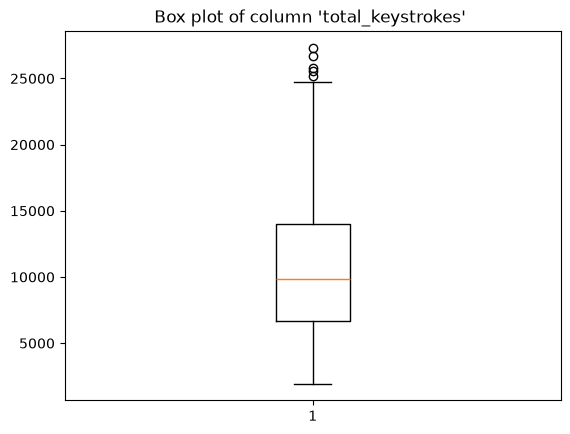

In [671]:
plt.boxplot(df['total_keystrokes'])
plt.title("Box plot of column 'total_keystrokes' ")
plt.show()

In [672]:
print(df.isnull().sum())

total_keystrokes           0
pause_ratio                0
median_inter_key_ms        0
inter_key_std_ms           0
backspace_ratio            0
paste_events               0
paste_char_ratio           0
time_on_problem_min        0
time_to_first_key_ms       0
edit_bursts                0
blank_line_ratio           0
avg_identifier_len         0
comment_ratio              0
todo_count                 0
max_continuous_type_sec    0
submit_minute_of_day       0
run_count                  0
pass_attempt_ratio         0
ai_score                   0
vscode                     0
jetbrains                  0
lms_web_editor             0
other                      0
dtype: int64


In [673]:
import pandasql as ps
def query(sql):
    return ps.sqldf(sql, globals())

In [674]:
query("""
select *
from df;
""")

,total_keystrokes,pause_ratio,median_inter_key_ms,inter_key_std_ms,backspace_ratio,paste_events,paste_char_ratio,time_on_problem_min,time_to_first_key_ms,edit_bursts,...,todo_count,max_continuous_type_sec,submit_minute_of_day,run_count,pass_attempt_ratio,ai_score,vscode,jetbrains,lms_web_editor,other
0,11177,0.458,304,223,0.662,0,0.178,60.7,229,15,...,2,382.0,836,6,0.580,11,0,0,0,1
1,3491,0.346,204,250,0.213,0,0.014,22.7,851,11,...,1,172.0,231,3,0.723,2,0,0,1,0
2,3163,0.521,207,157,0.298,1,0.177,48.0,1705,13,...,0,571.0,1238,3,0.823,23,0,1,0,0
3,6475,0.259,142,192,0.279,1,0.064,101.1,412,10,...,2,165.0,653,6,0.445,2,0,0,1,0
4,22042,0.466,264,306,0.103,2,0.000,62.3,386,11,...,4,127.0,1158,3,0.404,13,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,7871,0.170,225,379,0.478,0,0.001,30.3,1484,11,...,1,395.0,1187,6,0.292,0,1,0,0,0
376,8074,0.166,172,93,0.200,3,0.327,43.2,387,13,...,0,190.0,813,3,0.739,100,0,0,1,0
377,16027,0.232,61,98,0.113,0,0.003,16.3,409,15,...,1,48.0,878,4,0.223,21,1,0,0,0
378,19210,0.501,102,65,0.298,1,0.275,23.6,197,9,...,2,144.0,334,3,0.339,100,0,1,0,0


In [675]:
query("""
select max_continuous_type_sec, ai_score
from df
""")

,max_continuous_type_sec,ai_score
0,382.0,11
1,172.0,2
2,571.0,23
3,165.0,2
4,127.0,13
...,...,...
375,395.0,0
376,190.0,100
377,48.0,21
378,144.0,100


In [676]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Select the correlation threshold from validation performance instead of by hand.
X_all = df.drop(columns='ai_score')
y_all = df['ai_score']
X_train_fs, X_valid_fs, y_train_fs, y_valid_fs = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42
)

# Correlations are calculated on the training portion only to avoid using validation data.
train_corr = X_train_fs.join(y_train_fs).corr()['ai_score'].drop('ai_score').abs().fillna(0)
thresholds = np.arange(0.00, 0.51, 0.01)
threshold_results = []

for threshold in thresholds:
    kept_columns = train_corr[train_corr >= threshold].index.tolist()
    if not kept_columns:
        continue

    scaler_fs = StandardScaler()
    X_train_scaled_fs = scaler_fs.fit_transform(X_train_fs[kept_columns])
    X_valid_scaled_fs = scaler_fs.transform(X_valid_fs[kept_columns])
    model_fs = KNeighborsRegressor(n_neighbors=5)
    model_fs.fit(X_train_scaled_fs, y_train_fs)
    valid_pred_fs = model_fs.predict(X_valid_scaled_fs)

    threshold_results.append({
        'threshold': threshold,
        'features_kept': len(kept_columns),
        'mae': mean_absolute_error(y_valid_fs, valid_pred_fs),
        'rmse': mean_squared_error(y_valid_fs, valid_pred_fs) ** 0.5,
    })

threshold_results = pd.DataFrame(threshold_results).sort_values('mae')
best_threshold = float(threshold_results.iloc[0]['threshold'])
print('Threshold results (best MAE first):')
display(threshold_results)
print(f'Selected correlation threshold: {best_threshold:.2f}')

# Apply the selected threshold to the complete dataframe for the final model cells.
full_corr = df.drop(columns='ai_score').join(df['ai_score']).corr()['ai_score'].drop('ai_score').abs().fillna(0)
drop_cols = full_corr[full_corr < best_threshold].index
df = df.drop(columns=drop_cols)

df.to_csv("data-4-cleaned.csv", index=False)
df

Threshold results (best MAE first):


,threshold,features_kept,mae,rmse
18,0.18,6,10.778947,15.601822
17,0.17,6,10.778947,15.601822
16,0.16,6,10.778947,15.601822
15,0.15,6,10.778947,15.601822
8,0.08,8,12.160526,18.091071
9,0.09,8,12.160526,18.091071
13,0.13,7,12.913158,18.298907
14,0.14,7,12.913158,18.298907
12,0.12,7,12.913158,18.298907
11,0.11,7,12.913158,18.298907


Selected correlation threshold: 0.18


,total_keystrokes,inter_key_std_ms,backspace_ratio,paste_char_ratio,time_on_problem_min,time_to_first_key_ms,ai_score
0,11177,223,0.662,0.178,60.7,229,11
1,3491,250,0.213,0.014,22.7,851,2
2,3163,157,0.298,0.177,48.0,1705,23
3,6475,192,0.279,0.064,101.1,412,2
4,22042,306,0.103,0.000,62.3,386,13
...,...,...,...,...,...,...,...
394,7871,379,0.478,0.001,30.3,1484,0
395,8074,93,0.200,0.327,43.2,387,100
396,16027,98,0.113,0.003,16.3,409,21
397,19210,65,0.298,0.275,23.6,197,100


# Model training

In [677]:
y = df.ai_score
X = df.drop(columns="ai_score")


In [678]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20, random_state=42)

In [679]:
from sklearn.preprocessing import  StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

n_neighbors: 1, MAE: 15.4079, RMSE: 24.1909
n_neighbors: 2, MAE: 12.6711, RMSE: 18.0073
n_neighbors: 3, MAE: 11.6754, RMSE: 16.6310
n_neighbors: 4, MAE: 10.8125, RMSE: 15.1890
n_neighbors: 5, MAE: 10.7789, RMSE: 15.6018
n_neighbors: 6, MAE: 11.0373, RMSE: 15.8212
n_neighbors: 7, MAE: 11.0883, RMSE: 15.8621
n_neighbors: 8, MAE: 11.2171, RMSE: 15.9067
n_neighbors: 9, MAE: 11.6140, RMSE: 16.7078
n_neighbors: 10, MAE: 11.7829, RMSE: 16.7827
n_neighbors: 11, MAE: 12.0156, RMSE: 16.8584
n_neighbors: 12, MAE: 12.2818, RMSE: 17.1595
n_neighbors: 13, MAE: 12.2105, RMSE: 17.1232
n_neighbors: 14, MAE: 12.4568, RMSE: 17.3568
n_neighbors: 15, MAE: 12.5623, RMSE: 17.6723
n_neighbors: 16, MAE: 12.8553, RMSE: 17.8501
n_neighbors: 17, MAE: 13.2036, RMSE: 18.0202
n_neighbors: 18, MAE: 13.1272, RMSE: 17.9975
n_neighbors: 19, MAE: 13.0845, RMSE: 18.0415
n_neighbors: 20, MAE: 13.1697, RMSE: 17.9825
Best n_neighbors: 4, MAE: 10.8125, RMSE: 15.1890


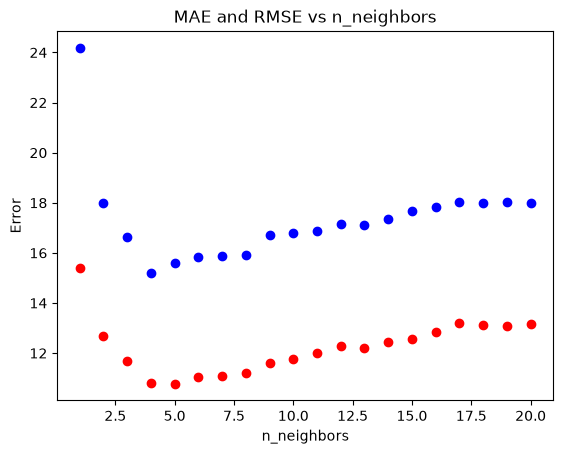

In [680]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import  mean_absolute_error, mean_squared_error
min_mae = 100000
min_rmse = 100000
n_final = 0
for n in range(1, 21):
    knn_reg = KNeighborsRegressor(n_neighbors=n)
    knn_reg.fit(X_train_scaled,y_train)
    y_pred = knn_reg.predict(X_test_scaled)
    mae = mean_absolute_error(y_test,y_pred)
    rmse = mean_squared_error(y_test,y_pred) ** 0.5
    if mae < min_mae and rmse < min_rmse:
        min_mae = mae
        min_rmse = rmse
        n_final = n
    plt.plot(n, mae, 'ro')
    plt.plot(n, rmse, 'bo')
    plt.title("MAE and RMSE vs n_neighbors")
    plt.xlabel("n_neighbors")
    plt.ylabel("Error")
    print(f"n_neighbors: {n}, MAE: {mae:.4f}, RMSE: {rmse:.4f}")
print(f"Best n_neighbors: {n_final}, MAE: {min_mae:.4f}, RMSE: {min_rmse:.4f}")
knn_reg = KNeighborsRegressor(n_neighbors=n_final)
knn_reg.fit(X_train_scaled,y_train)
plt.show()


In [681]:
y_pred = knn_reg.predict(X_test_scaled)
print("MAE:", mean_absolute_error(y_test,y_pred))
print("RMSE:", mean_squared_error(y_test,y_pred) ** 0.5)

MAE: 10.8125
RMSE: 15.18902282813757


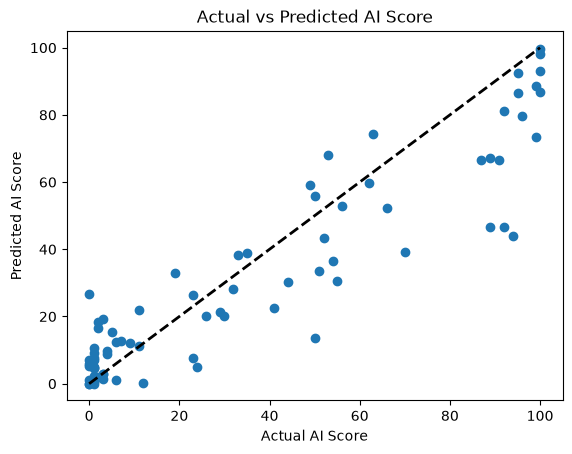

In [682]:
import matplotlib.pyplot as plt
plt.scatter(y_test, y_pred)
plt.xlabel("Actual AI Score")
plt.ylabel("Predicted AI Score")
plt.title("Actual vs Predicted AI Score")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

In [683]:
from joblib import dump, load

# Save the trained KNN model and the fitted scaler
dump(knn_reg, "knn_model.joblib")
dump(scaler, "scaler.joblib")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
